# Lab 4 — Forty Soybean Cultivars
## Mismo código de Lab3/redFFBP
**Predicción:** `GY`, rendimiento del grano en kg/ha.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [9]:
base=Path.cwd()
zp=base.parent/"datasets"/"soybean.zip" if base.name=="notebooks" else base/"datasets"/"soybean.zip"
out=zp.parent/"soybean"
out.mkdir(exist_ok=True)
with zipfile.ZipFile(zp) as z: z.extractall(out)
df=pd.read_csv(out/"data.csv")
print(df.head())
print("Registros:",len(df))
print("Columnas:",list(df.columns))

   Season    Cultivar  Repetition     PH    IFP    NLP     NGP   NGL   NS  \
0       1  NEO 760 CE           1  58.80  15.20   98.2  177.80  1.81  5.2   
1       1  NEO 760 CE           2  58.60  13.40  102.0  195.00  1.85  7.2   
2       1  NEO 760 CE           3  63.40  17.20  100.4  203.00  2.02  6.8   
3       1  NEO 760 CE           4  60.27  15.27  100.2  191.93  1.89  6.4   
4       1   MANU IPRO           1  81.20  18.00   98.8  173.00  1.75  7.4   

      MHG       GY  
0  152.20  3232.82  
1  141.69  3517.36  
2  148.81  3391.46  
3  148.50  3312.58  
4  145.59  3230.99  
Registros: 320
Columnas: ['Season', 'Cultivar', 'Repetition', 'PH', 'IFP', 'NLP', 'NGP', 'NGL', 'NS', 'MHG', 'GY']


GY     1.000000
NGP    0.238883
NLP    0.198741
NS     0.167022
IFP    0.139090
PH     0.123281
NGL    0.077404
MHG    0.074552
Name: GY, dtype: float64


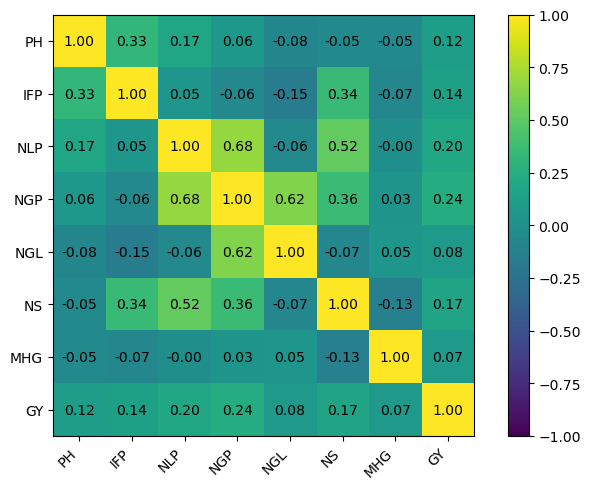

In [10]:
cols=['PH', 'IFP', 'NLP', 'NGP', 'NGL', 'NS', 'MHG', 'GY']
corr=df[cols].corr()
print(corr['GY'].sort_values(ascending=False))

fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(corr,vmin=-1,vmax=1)
ax.set_xticks(range(len(cols)),cols,rotation=45,ha="right")
ax.set_yticks(range(len(cols)),cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im)
plt.tight_layout()
plt.show()

In [11]:
X = df[['PH', 'IFP', 'NLP', 'NGP', 'NGL', 'NS', 'MHG']].values
y = df[['GY']].values

# 60% entrenamiento / 40% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.40, random_state=42
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
y_train_norm = scaler_y.fit_transform(y_train)
y_test_norm = scaler_y.transform(y_test)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

Entrenamiento: 192
Prueba: 128


In [12]:
# MISMA IMPLEMENTACION DE Lab3/redFFBP
def ReLu(x):
    return np.maximum(0, x)

class Capa:
    def __init__(self, entradas, neuronas, activacion=None, bias=False):
        self.entradas = entradas
        self.neuronas = neuronas
        self.activacion = activacion
        self.bias = bias

        self.pesos = np.random.randn(entradas, neuronas) * 0.1

        if bias:
            self.b = np.zeros((1, neuronas))
        else:
            self.b = None

    def feed_forward(self, X):
        self.entrada = X
        self.z = X @ self.pesos

        if self.bias:
            self.z += self.b

        if self.activacion is not None:
            self.salida = self.activacion(self.z)
        else:
            self.salida = self.z

        return self.salida

    def backward(self, ultima=False, error=None,
                 delta_siguiente=None, pesos_siguientes=None):

        if ultima:
            self.delta = error
        else:
            self.delta = delta_siguiente @ pesos_siguientes.T

            if self.activacion == ReLu:
                self.delta *= (self.z > 0)

        self.grad_pesos = self.entrada.T @ self.delta

        if self.bias:
            self.grad_bias = np.sum(
                self.delta,
                axis=0,
                keepdims=True
            )

        return self.delta

In [13]:
np.random.seed(42)

capa1 = Capa(
    entradas=7,
    neuronas=13,
    activacion=ReLu,
    bias=True
)

capa2 = Capa(
    entradas=13,
    neuronas=1,
    activacion=None,
    bias=True
)

epocas = 500

alpha = 0.01 / len(X_train)

historial_perdida = []

for epoca in range(epocas):

    # Feed Forward
    salida1 = capa1.feed_forward(X_train)
    resultado = capa2.feed_forward(salida1)

    # Error
    error = resultado - y_train_norm

    # Perdida
    perdida = 0.5 * np.mean(error ** 2)
    historial_perdida.append(perdida)

    # Backpropagation
    delta2 = capa2.backward(
        ultima=True,
        error=error
    )

    delta1 = capa1.backward(
        ultima=False,
        delta_siguiente=delta2,
        pesos_siguientes=capa2.pesos
    )

    # Actualizacion de pesos
    capa1.pesos -= alpha * capa1.grad_pesos
    capa2.pesos -= alpha * capa2.grad_pesos

    # Actualizacion de bias
    capa1.b -= alpha * capa1.grad_bias
    capa2.b -= alpha * capa2.grad_bias

    if epoca == 0 or (epoca + 1) % 50 == 0:
        print("Epoca:", epoca + 1, "- Perdida:", perdida)

# En TEST solo hacemos Feed Forward.
# NO se hace Backpropagation con los datos de prueba.
salida_test = capa1.feed_forward(X_test)
pred_test_norm = capa2.feed_forward(salida_test)

pred_test = scaler_y.inverse_transform(pred_test_norm)
y_test_real = scaler_y.inverse_transform(y_test_norm)

Epoca: 1 - Perdida: 0.4998446408448882
Epoca: 50 - Perdida: 0.49591753827793
Epoca: 100 - Perdida: 0.49247442520161755
Epoca: 150 - Perdida: 0.4890795635180892
Epoca: 200 - Perdida: 0.4855880575238512
Epoca: 250 - Perdida: 0.48189791349645095
Epoca: 300 - Perdida: 0.47805832914356244
Epoca: 350 - Perdida: 0.47427482950772165
Epoca: 400 - Perdida: 0.4703905658519849
Epoca: 450 - Perdida: 0.4664658101211597
Epoca: 500 - Perdida: 0.4624729985684051


R² = 0.03956407820063079
R = 0.2114213117563474
MAE = 368.84617815634124
RMSE = 491.1352318008424


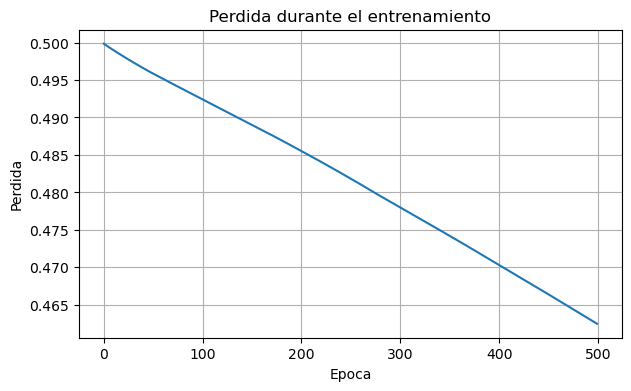

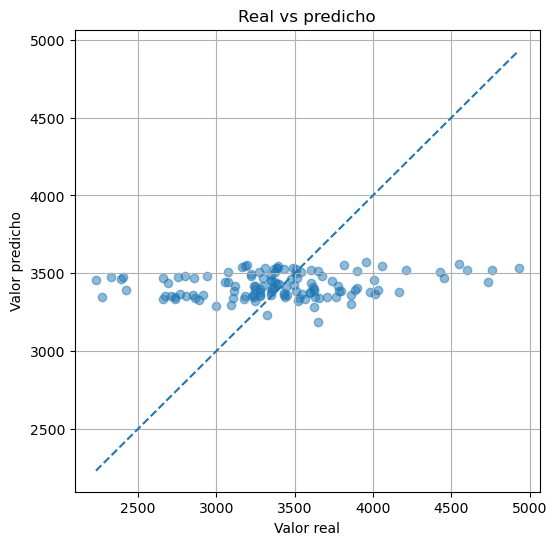

In [14]:
r2 = r2_score(y_test_real, pred_test)
r = np.corrcoef(y_test_real.ravel(), pred_test.ravel())[0, 1]
mae = mean_absolute_error(y_test_real, pred_test)
rmse = np.sqrt(mean_squared_error(y_test_real, pred_test))

print("R² =", r2)
print("R =", r)
print("MAE =", mae)
print("RMSE =", rmse)

plt.figure(figsize=(7,4))
plt.plot(historial_perdida)
plt.xlabel("Epoca")
plt.ylabel("Perdida")
plt.title("Perdida durante el entrenamiento")
plt.grid()
plt.show()

plt.figure(figsize=(6,6))
plt.scatter(y_test_real, pred_test, alpha=0.5)
a=min(y_test_real.min(),pred_test.min())
b=max(y_test_real.max(),pred_test.max())
plt.plot([a,b],[a,b],"--")
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Real vs predicho")
plt.grid()
plt.show()